# Material de aula - FACENS - Aprendizado de Máquina

# <center> RESOLUÇÃO DA ATIVIDADE </center>


## Algoritmos Genéticos - Função de 1 variável - Laboratório 06

In [1]:
#CÉLULA AG-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
from enum import Enum
from operator import xor
%matplotlib inline

class crossoverType(Enum) : 
    OnePoint   = 1
    MultiPoint = 2
    Uniform    = 3 #usa mascara

class selectionType(Enum) : 
    roullete   = 1
    tournament = 2
    stochastic = 3

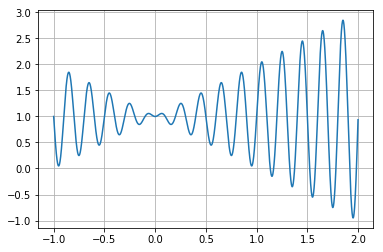

In [2]:
#CÉLULA AG-LIB-02
# Plotando o gráfico da função de Fitness
X = np.arange(-1, 2, 0.001)
Y = (X * np.sin(10*np.pi*X) + 1)

plt.figure()
plt.plot(X, Y)
plt.grid()
plt.show()

In [3]:
#CÉLULA AG-LIB-03
def scale(x1) :
    '''
    Função para cálculo de escalamento e normalização de individuos
    Esta função faz o escalamento de individuos dentro do intervalo [-1, 2]
    22 bits para codificar precisao de 6 digitos
    000000 ... 0 = -1
    111111 ... 1 =  2
    ou seja, x1 em [0, 4194303] -> 2^nbits - 1
    '''
    
    #Teorema de Tales
    # ( x2 - x2_min ) / ( x2_max - x2_min ) = ( x1 - x1_min ) / (x1_max - % x1_min);
    
    #Isolando x2, a variavel de interesse
    # x2 = ( ( x1 - x1_min ) / (x1_max - x1_min) )* ( x2_max - x2_min ) + x2_min;

    x1Min=0
    x1Max=2**22-1
    
    x2Min=-1
    x2Max=2
    
    x2 = ((x1 - x1Min)*(x2Max - x2Min)) / (x1Max - x1Min) + x2Min

    return round(x2, 6)

In [4]:
#CÉLULA AG-LIB-04
def fitness(individual) :
    '''
    Função para cálculo de fitness (aptidão de cada individuo)

    Parametros
    -----------
    individual  -> cromossomo do individuo cuja aptidao sera calculada
    
    Retorno
    -----------  
    valor da aptidao associada com precisão de 6 casas decimais
    '''
    
    x1 = float(scale(individual))
    result = (x1 * np.sin(10*np.pi*x1) + 1)
    return round(result, 6)

#fitness(0.5)

In [5]:
#CÉLULA AG-LIB-05
def plot_population(P, generation):
    '''
    Plota em um gráfico a disposição dos indivíduos da população no espaço de busca
    
    Parametros
    -----------
    P          -> array contendo os individuos da população
    generation -> escalar indicando a qual geração do algoritmo está situada a população a ser plotada
    
    Retorno
    -----------  
    N/A
    '''
    
    xmin =-1
    xmax = 2
    ymin =-1
    ymax = 3
    
    xAxis = []
    yAxis = []
    for individual in P :
        xAxis.append(scale(individual))
        yAxis.append(fitness(individual))
    
    plt.figure()
    plt.plot(xAxis, yAxis, 'bo')
    plt.axis([xmin, xmax, ymin, ymax])
    
    plt.xlabel('x')
    plt.ylabel('y')
    sTitle = ('Populacao na geração {}'.format(generation))
    plt.title(sTitle)
    plt.grid()

In [6]:
#CÉLULA AG-LIB-06
def checkStopCondition(P, stop_condition, epsilon):
    '''
    Verifica a condição de parada do algoritmo genético para uma dada situação
    
    Parametros
    -----------
    P              -> array contendo os individuos da população
    stop_condition -> taxa da população que deve ter convergido para um mesmo local
    epsilon        -> margem de erro aceitável entre valores de aptidão dos cromossomos
    
    Retorno
    -----------  
    True -> se a condição de parada foi atingida, False caso contrário
    '''
    y = [fitness(individual) for individual in P]
    
    if( abs(max(y) - min(y)) < epsilon) :
        print('Todos os individuos convergiram')
        return True
    
    bestIndividuals = [1 for fitness_individual in y if abs(max(y) - fitness_individual) < epsilon]
    #print(len(outliers))
    
    if( (len(bestIndividuals) / len(P)) >= stop_condition) :
        print('Pelo menos {}% de todos os individuos convergiram'.format(stop_condition * 100))
        return True
    
    return False    

In [7]:
#CÉLULA AG-LIB-07
def roulette(P, vFitness) :
    '''
    Função que efetua o sorteio no estilo roleta entre 0 e aptidacao maxima acumulada
    
    Parametros
    -----------
    P        -> array contendo os individuos da população
    vFitness -> vetor com valores de aptidão alinhado com P
    
    Retorno
    -----------  
    cromossomo vencedor da competição ou -1 em caso de falha
    '''
    maxFitness = sum(vFitness)
    rouletteVal = np.random.rand() * maxFitness
    
    iAcumFitness = 0
    for fitnessVal, index in zip(vFitness, range(0, len(vFitness))):
        iAcumFitness += fitnessVal
        if(iAcumFitness >= rouletteVal) :                
            return P[index]
    
    return -1

In [8]:
#CÉLULA AG-LIB-08
def tournament(P, vFitness, nCandidates) :
    '''
    Função que realiza o torneio de uma população P. Sorteia nCandidates inidividuos e retorna aquele com maior aptidão
    
    Parametros
    -----------
    P           -> array contendo os individuos da população
    vFitness    -> vetor com valores de aptidão alinhado com P
    nCandidates -> numero de individuos participantes de cada torneio
    
    Retorno
    -----------  
    cromossomo vencedor do torneio
    '''
    v = np.random.randint(0, len(P), size=(nCandidates))
    candidates = [(i, vFitness[i]) for i in v]    
    return P[max(candidates)[0]]

In [9]:
#CÉLULA AG-LIB-10
def selectCandidates(P, method, qty_candidates, sus_qty_pointers) :
    '''
    Função que realiza a seleção dos indivíduos mais aptos de uma população P.
    
    Parametros
    -----------
    P                -> array contendo os individuos da população
    method           -> enumeração que indica o metodo de seleção natural
    qty_candidates   -> quantidade de 'selecionados' a serem retornados pela função
    sus_qty_pointers -> quantidade de agulhas da roleta da amostragem universal estocastica (SUS)
    
    Retorno
    -----------  
    Vetor contendo os cromossomos selecionados
    '''
    candidatesList = []
    
    #Ordena a população em termos de suas aptidões
    #Esta ordenação é necessária para seleção em roleta ou SUS
    vFitness = [fitness(p) for p in P]
    p_tuple = zip(vFitness, P)    
    sorted_by_fitness = sorted(p_tuple, key=lambda tup: tup[0])

    P = []
    vFitnessSorted = []
    for (fitnessValue, p) in sorted_by_fitness :
        P.append(p)
        vFitnessSorted.append(fitnessValue)
    
    if (method == selectionType.roullete) :
        #Deslocaremos a aptidão da população, pois possui valores negativos, assim é possivel calcular o valor acumulado
        vFitnessShifted = [ (2*abs(min(vFitnessSorted)) + x) for x in vFitnessSorted ]                
        
        for _ in range(0, qty_candidates) :
            winner = roulette(P, vFitnessShifted)
            if(winner != -1) :
                candidatesList.append(winner)
        
    elif (method == selectionType.tournament) :
        #Torneio
        for _ in range(0, qty_candidates) :
            winner = tournament(P, vFitnessSorted, 3)
            candidatesList.append(winner)
    else : 
        #Amostragem Universal Estocastica - é uma roleta com multiplos ponteiros (sus_qty_pointers)
        #Deslocaremos a aptidão da população, pois possui valores negativos, assim é possivel calcular o valor acumulado
        vFitnessShifted = [ (2*abs(min(vFitnessSorted)) + x) for x in vFitnessSorted ]                

        vWinners = []
        vWinners = stochasticUniversalSampling(P, vFitnessShifted, sus_qty_pointers)
        for winner in vWinners : 
            candidatesList.append(winner)
        
    return candidatesList

In [10]:
#CÉLULA AG-LIB-11
def crossover(candidatesList, reproduction_rate, populationSize, mode, crossoverMask) :
    '''
    Função que realiza o cruzamento dos indivíduos mais aptos de uma população P.
    
    Parametros
    -----------
    candidatesList    -> lista de individuos mais aptos
    reproduction_rate -> probabilidade de ocorrer um crossover
    populationSize    -> tamanho esperado da populacao apos o crossover
    mode              -> enumeration que indica o tipo de cruzamento (um ponto, multi-ponto, com mascara)
    mask              -> mascara para crossover do tipo 'uniforme'
    
    Retorno
    -----------  
    Vetor contendo a nova geração de cromossomos após os cruzamentos
    '''
    childrenList = []
    
    for i in range(0, int(populationSize / 2)) :
        #escolhe dois individuos ao acaso
        v = np.random.randint(0, len(candidatesList), size=(2))
        
        p1 = candidatesList[v[0]]
        p2 = candidatesList[v[1]]

        #decide se vai ocorrer reproducao, caso contrario, os filhos serao apenas copias dos pais
        if (np.random.rand() <= reproduction_rate ) :
            if (mode == crossoverType.OnePoint) :                
                #Crossover em um ponto, na metade do cromossomo                
                p1Bin = "{0:022b}".format(p1) #formata numero em 22 bits
                p2Bin = "{0:022b}".format(p2) #formata numero em 22 bits

                #Faz o slice
                geneP1L = p1Bin[0:11]
                geneP1R = p1Bin[11:22]
                
                geneP2L = p2Bin[0:11]
                geneP2R = p2Bin[11:22]
                
                #Realiza o cruzamento, concatena os genes e converte para numero inteiro
                c1 = int(geneP1L+geneP2R, 2) 
                c2 = int(geneP2L+geneP1R, 2)
                
                #Adiciona ao array de filhos
                childrenList.append(c1)
                childrenList.append(c2)
            elif(mode == crossoverType.MultiPoint) :
                #Crossover multi-ponto, realizado na posicao 8 e 16
                p1Bin = "{0:022b}".format(p1) #formata numero em 22 bits
                p2Bin = "{0:022b}".format(p2) #formata numero em 22 bits

                #Slicing
                geneP1L = p1Bin[0:8]
                geneP1M = p1Bin[8:16]
                geneP1R = p1Bin[16:22]
                
                geneP2L = p2Bin[0:8]
                geneP2M = p2Bin[8:16]
                geneP2R = p2Bin[16:22]

                #Realiza o cruzamento, trocando somente a parte do meio, concatena os genes e converte para numero inteiro
                c1 = int(geneP1L + geneP2M + geneP1R, 2) 
                c2 = int(geneP2L + geneP1M + geneP2R, 2)
                
                #Adiciona ao array de filhos
                childrenList.append(c1)
                childrenList.append(c2)                
            else:
                #Usa a mascara fornecida e realiza um OU-Exclusivo
                #'0b' será necessario para o XOR
                p1Bin = '0b' + "{0:022b}".format(p1) #formata numero em 22 bits
                p2Bin = '0b' + "{0:022b}".format(p2) #formata numero em 22 bits

                #Realiza cruzamento
                c1 = int(p1Bin,2) ^ crossoverMask
                c2 = int(p2Bin,2) ^ crossoverMask
                
                #Adiciona ao array de filhos
                childrenList.append(c1)
                childrenList.append(c2)
        else:
            # Não ocorreu reprodução, os filhos são copias dos pais
            childrenList.append(p1)
            childrenList.append(p2)
    
    return childrenList

In [11]:
#CÉLULA AG-LIB-12
def mutation(candidatesList, mutation_rate) :
    '''
    Função que realiza a mutação dos indivíduos após a realização do crossover de uma população P. 
    Cada indivíduo tem uma probabilidade igual a 'mutation_rate' de sofrer uma mutação em seus genes.
    
    Parametros
    -----------
    candidatesList    -> lista de individuos mais aptos
    mutation_rate     -> probabilidade de ocorrer uma mutação
    
    Retorno
    -----------  
    Vetor contendo a nova geração de cromossomos após as mutações
    '''    
    mutatedList = []
    
    for p in candidatesList :
        if (np.random.rand() <= mutation_rate ) :
            #realiza mutação
            pBin = list("{0:022b}".format(p)) #formata numero em 22 bits

            #sorteia um bit para sofrer mutação
            mutationIndex = np.random.randint(0,len(pBin))
            
            #Aplica mutação
            if (pBin[mutationIndex] == '0') :
                pBin[mutationIndex] = '1'
            else:
                pBin[mutationIndex] = '0'

            #Transforma pBin (lista) em string e a seguir, em inteiro
            pBinStr = ''.join(pBin)
            mutatedList.append(int(pBinStr, 2))
        
        else:
            mutatedList.append(p)
    
    return mutatedList

# 1 - Criando o AG

Utilizando Jupyter e NumPy: para a função de variável contínua apresentada, complete a implementação do algoritmo.

In [12]:
# CÉLULA AG-MAIN-01
#Parâmetros
size_pop          = 100
max_generations   = 100
stop_condition    = 0.95
reproduction_rate = 0.7
mutation_rate     = 0.01

min_individual = 0
max_individual = 2**22-1
sus_qty_pointers = 4 #quantidade de ponteiros da roleta do tipo SUS
crossoverMask = '0b0000111100001111000111' #mascara para crossover

In [13]:
# CÉLULA AG-MAIN-02
#Inicializando população
P=[]

P = np.random.randint(0, max_individual, size=(size_pop))
P = P.tolist()

[1155634, 2568779, 3721809, 860486, 2301274, 2218318, 3684912, 3543023, 787241, 904933, 1640651, 2800518, 2701495, 151391, 1379304, 205025, 1121525, 2015586, 1045583, 553954, 3455394, 1125082, 1998237, 2307550, 611487, 1650504, 3886382, 2193622, 2987854, 833975, 2088858, 1516693, 3300567, 1736962, 3857422, 807756, 580346, 2131433, 3076627, 3478648, 1529165, 3960738, 975954, 400547, 3789398, 640648, 4055012, 2646728, 3347389, 1466420, 2979446, 3532329, 2680332, 1505870, 1953933, 1777528, 1610677, 859326, 2090417, 3120558, 1546512, 1720083, 3639890, 3853786, 2199492, 2265154, 3127637, 479841, 2765872, 2624299, 622221, 1513150, 2385999, 3549541, 2370741, 2009308, 99250, 4022231, 1509548, 2086248, 2989279, 2661506, 4019616, 410456, 910219, 267641, 2255045, 4044994, 2354643, 803501, 3557257, 3126958, 601179, 509706, 773978, 3531866, 1355147, 3510094, 3525807, 3993345]


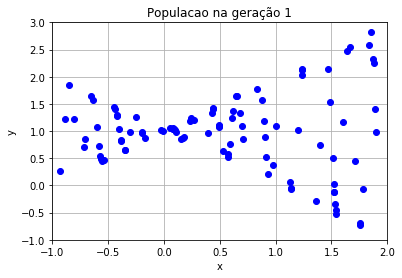

In [14]:
# CÉLULA AG-MAIN-03
plot_population(P, 1)
print(P)

Pelo menos 95.0% de todos os individuos convergiram
Convergencia atingida
100
[3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989729, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989921, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989729, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665, 3989665]
16


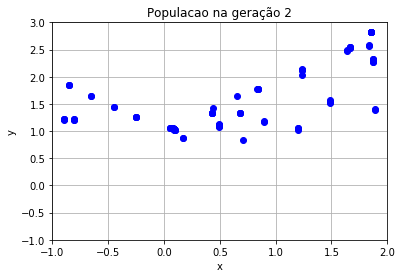

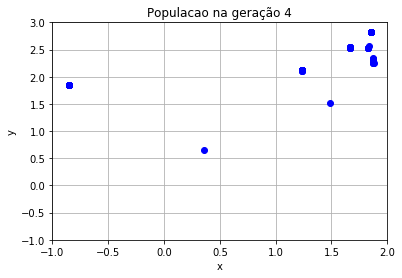

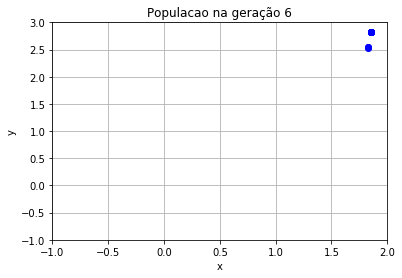

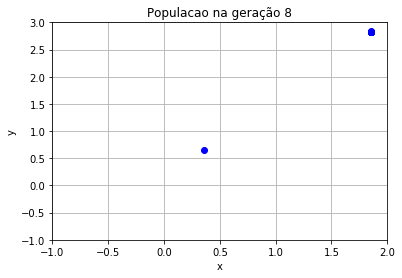

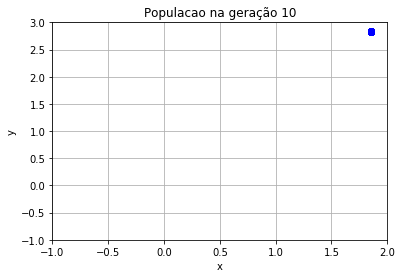

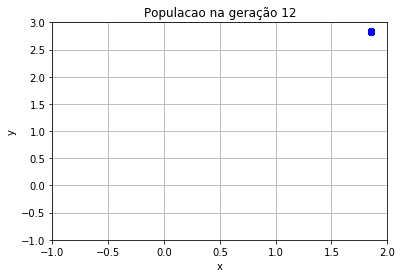

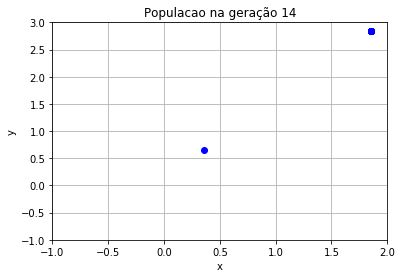

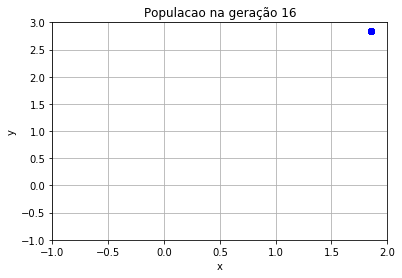

In [15]:
# CÉLULA AG-MAIN-04
#Loop principal
generation_index = 0
while( generation_index != max_generations) : 
    generation_index = generation_index + 1
            
    if(generation_index % 2 == 0) :
        plot_population(P, generation_index)
    
    stop = checkStopCondition(P, stop_condition, 0.000001)
    if(stop == True) :
        print('Convergencia atingida')
        break
    
    #Selecionando os mais aptos para cruzamento (50% da população)
    candidatesList = []
    candidatesList = selectCandidates(P, selectionType.tournament, int(size_pop / 2), sus_qty_pointers)
        
    #Realiza cruzamento
    childrenList = []
    childrenList = crossover(candidatesList, reproduction_rate, size_pop, crossoverType.OnePoint, crossoverMask)

    #Realiza mutação
    childrenList = mutation(childrenList, mutation_rate)

    #Compõe a população para a proxima geração
    P.clear
    P = childrenList
    
print(len(childrenList))
#print(P)
print(childrenList)
print(generation_index)

A convergencia foi atingida na geração: 16
O cromossomo vencedor foi: 3989665->(1111001110000010100001)b, ou seja, x=1.853631 com aptidão 2.841584
A solução do problema é x=1.853631


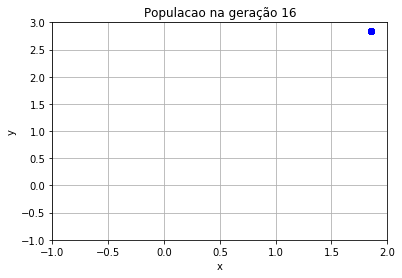

In [16]:
# CÉLULA AG-MAIN-05
#Verificando os resultados

bestFitness    = fitness(childrenList[0])
bestIndividual = childrenList[0]
for p in childrenList :
    if(fitness(p) >= bestFitness) :
        bestFitness = fitness(p)
        bestIndividual = p

print('A convergencia foi atingida na geração: {}'.format(generation_index))
print('O cromossomo vencedor foi: {}->({})b, ou seja, x={} com aptidão {}'.format(bestIndividual, "{0:022b}".format(p), scale(bestIndividual), bestFitness))
print('A solução do problema é x={}'.format(scale(bestIndividual)))

plot_population(P, generation_index)

## Validação

### Execute algumas vezes e verifique o resultado.